Alessia Stefanelli - 615430

# Data Understanding - Dati Tabulari  - `triage.csv`

Esplorazione di ciascun dataset, inizialmente, separatamente

### **Informazioni Generali**

In [28]:
# Caricamento librerie necessarie all'analisi dei dataset nei file CSV
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

from collections import defaultdict

import seaborn as sns

from scipy.stats import pearsonr


In [33]:
triage_df = pd.read_csv('../datasets/patients_traige.csv')
patients_df = pd.read_csv('../datasets/patients.csv')

In [30]:
triage_df

,Unnamed: 0,subject_id,stay_id,temperature,heartrate,resprate,o2sat,sbp,dbp,pain,acuity,chiefcomplaint
0,0,10000032,32952584,97.8,87.0,14.0,97.0,71.0,43.0,7,2.0,Hypotension
1,1,10000032,33258284,98.4,70.0,16.0,97.0,106.0,63.0,0,3.0,"Abd pain, Abdominal distention"
2,2,10000032,35968195,99.4,105.0,18.0,96.0,106.0,57.0,10,3.0,"n/v/d, Abd pain"
3,3,10000032,38112554,98.9,88.0,18.0,97.0,116.0,88.0,10,3.0,Abdominal distention
4,4,10000032,39399961,98.7,77.0,16.0,98.0,96.0,50.0,13,2.0,"Abdominal distention, Abd pain, LETHAGIC"
...,...,...,...,...,...,...,...,...,...,...,...,...
105954,425078,19999733,30940569,98.0,60.0,18.0,100.0,120.0,71.0,0,3.0,? SEIZURE TODAY
105955,425080,19999784,34149746,98.8,92.0,18.0,100.0,122.0,77.0,0,3.0,Wound eval
105956,425081,19999784,35692999,98.6,80.0,18.0,100.0,161.0,100.0,0,3.0,L Leg weakness
105957,425082,19999784,37972930,98.0,91.0,16.0,99.0,148.0,90.0,5,2.0,Abnormal MRI



#### **Osservazione**:  
#### **Temporary Cleaning** :`Unnamed: 0` dovra' essere rimosso durante la Data Preparation, poiche non ha un significato apparente

In [31]:
# temp cleaning
triage_df  = triage_df.drop(columns=["Unnamed: 0"])

In [6]:
# num of record and attribute of triage_df
print("Dim del dataset:", triage_df.shape)

Dim del dataset: (105959, 11)


In [248]:
triage_df.columns

Index(['subject_id', 'stay_id', 'temperature', 'heartrate', 'resprate',
       'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint'],
      dtype='object')

In [15]:
# Info sul dataset
triage_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105959 entries, 0 to 105958
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   subject_id      105959 non-null  int64  
 1   stay_id         105959 non-null  int64  
 2   temperature     97486 non-null   float64
 3   heartrate       99593 non-null   float64
 4   resprate        98573 non-null   float64
 5   o2sat           98540 non-null   float64
 6   sbp             99336 non-null   float64
 7   dbp             99132 non-null   float64
 8   pain            101269 non-null  object 
 9   acuity          103456 non-null  float64
 10  chiefcomplaint  105950 non-null  object 
dtypes: float64(7), int64(2), object(2)
memory usage: 8.9+ MB


--- 
### **Dupplicati**

In [25]:
num_duplicates = triage_df.duplicated().sum()
print("Numero di righe duplicate:", num_duplicates)

Numero di righe duplicate: 0


In [24]:
# Trova duplicati basati su una colonna specifica come 'subject_id'
duplicates_subject = triage_df[triage_df.duplicated(subset=['subject_id'])]
print("Numero di duplicati basati su 'subject_id':", len(duplicates_subject))


Numero di duplicati basati su 'subject_id': 64544


In [36]:
# Conta le righe duplicate
# subset_column_num = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'subject_id']
tmp = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'subject_id', 'stay_id']
duplicates = triage_df[triage_df[tmp].duplicated()]
print("Numero di righe duplicate:", len(duplicates))
print("Righe duplicate:")
duplicates


Numero di righe duplicate: 0
Righe duplicate:


,Unnamed: 0,subject_id,stay_id,temperature,heartrate,resprate,o2sat,sbp,dbp,pain,acuity,chiefcomplaint


---

### **Valori Mancanti**



In [34]:
# Controllo che i pazienti siano presenti nel dataset principale 'patients_df'
triage_subject_ids = set(triage_df['subject_id'].unique())
patients_subject_ids = set(patients_df['subject_id'].unique())
missing_subject_ids = triage_subject_ids - patients_subject_ids
num_missing_subject_ids = len(missing_subject_ids)
print(f"Numero di subject_id in vital_sign_df ma non in patient_df: {num_missing_subject_ids}")


Numero di subject_id in vital_sign_df ma non in patient_df: 0


In [50]:
# Conta valori NaN in ogni colonna
triage_df.isnull().sum()

subject_id           0
stay_id              0
temperature       8473
heartrate         6366
resprate          7386
o2sat             7419
sbp               6623
dbp               6827
pain              4690
acuity            2503
chiefcomplaint       9
dtype: int64

In [4]:
# Calcola la percentuale di valori mancanti
tmp_column_triage = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint']
missing_percentage = (triage_df[tmp_column_triage].isnull().sum() / len(triage_df)) * 100
print("Percentuale di valori mancanti:")
print(missing_percentage)

Percentuale di valori mancanti:
temperature       7.996489
heartrate         6.007984
resprate          6.970621
o2sat             7.001765
sbp               6.250531
dbp               6.443058
pain              4.426240
acuity            2.362234
chiefcomplaint    0.008494
dtype: float64


In [53]:
# Conta le righe con almeno un valore mancante
rows_any_nan = triage_df[triage_df.isnull().any(axis=1)]
print("Totale righe nel dataset: ", len(triage_df))
print("Totale righe con almeno un NaN: ",  len(rows_any_nan))
print("Numero di righe senza nemmeno un NaN:", len(triage_df) - len(rows_any_nan))


Totale righe nel dataset:  105959
Totale righe con almeno un NaN:  11845
Numero di righe senza nemmeno un NaN: 94114


In [9]:
# Conta le righe interamente vuote
essential_columns_triage = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
rows_all_nan = triage_df.dropna(how='all', subset=essential_columns_triage)
print(essential_columns_triage)
print("Numero di righe con tutti NaN per tutte le colonne selezionate:", len(triage_df) - len(rows_all_nan))

['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
Numero di righe con tutti NaN per tutte le colonne selezionate: 5940


#### **Osservazione:** Verranno cancellate le 5940 colonne nel Data Preparation, poiche valori mancanti nelle colonne piu essenziali

In [170]:
# Verifica i valori mancanti per le colonne essenziali, prima e dopo la rimozione dei 5940
tmp_triage_df = triage_df.dropna(how='all', subset=essential_columns_triage)

tmp_triage_df[essential_columns_triage].isnull().sum()
print("Valori mancanti per le colonne essenziali PRIMA della rimozione:")
print(triage_df[essential_columns_triage].isnull().sum())
print("-"*50, "\n")
print("Valori mancanti per le colonne essenziali DOPO la rimozione:")
print(tmp_triage_df[essential_columns_triage].isnull().sum())
print(len(tmp_triage_df))
print("Percentuale restanti: ", len(tmp_triage_df)/len(triage_df)*100)


Valori mancanti per le colonne essenziali PRIMA della rimozione:
temperature    8473
heartrate      6366
resprate       7386
o2sat          7419
sbp            6623
dbp            6827
dtype: int64
-------------------------------------------------- 

Valori mancanti per le colonne essenziali DOPO la rimozione:
temperature    2533
heartrate       426
resprate       1446
o2sat          1479
sbp             683
dbp             887
dtype: int64
100019
Percentuale restanti:  94.39405807906832


In [11]:
# Se rimossi tutti i NaN
tmp_triage_df1 = triage_df.dropna()
print(len(tmp_triage_df1))
print("Percentuale restanti: ", len(tmp_triage_df1)/len(triage_df)*100)

94114
Percentuale restanti:  88.82114780245189


---

### **Statistiche Descrittive + Distribuzione + Analisi outlier**

In [262]:
print(triage_df.dtypes)

subject_id          int64
stay_id             int64
temperature       float64
heartrate         float64
resprate          float64
o2sat             float64
sbp               float64
dbp               float64
pain               object
acuity            float64
chiefcomplaint     object
dtype: object


In [263]:
# Controllo che gli attributi 'object' non siano un intero/float
obj_column = ['pain', 'chiefcomplaint']
for column in obj_column:
    print(f"\nValori unici per [{column}]\n")
    print(triage_df[column].unique())
    print("-"*50, "\n")


Valori unici per [pain]

['7' '0' '10' '13' '3' '8' '4' '6' nan '5' '2' '1' 'Non-verbal' '9' 'ett'
 'unable' 'ua' 'Critical' 'uta' 'critical' '>10' '5-6' 'UA' 'UTA'
 'denies ' 'yes' 'ok' 'o' '7.5' 'leg pain' 'c' '3-4' 'unable ' '8.5'
 'crit' '9.5' 'Unable' 'alot' 'ETT' '?' ' 0' 'sore' '15-20' 'u' '20' '0 '
 'denies' '10 ' 'sedated' '2-3' '6-7' 'u/a' 'asleep' '___' 'Bad'
 'sleeping' 'unqble' 'UTA ' 'burning' '7-8' 'no' 'uta ' '6.5' 'pre-hosp'
 'UNABLE' 'unable to score - abd pain' '1.5' 'not much' 'very painful'
 '"pain"' 'not bad' 's' '3t' '0-10' '4-5' '8-9' '1-2' 'prehosp' '11'
 'uanble' '"hurts everywhere"' 'hurts' 'bad' 'pain' 'mild' '4 ' 'uable'
 'it hurts' 'yes - R arm' '0.5' '8 ' 'unable to rate' 'moderate'
 'refusing' 'Refused' 'unsure' 'trigger' '"yes"' '"15"' 'Unresponsive'
 '5.8' '12' '7/8' '-' 'unbale' '7.5-8' 'uts' '10+' '101' 'T' 'dull'
 'refused ' 'xc' '"alittle"' '"pains"' '0.' 'a lot' 'unable to score'
 '"alot"' '4.5' '-0' '"not bad" ' 'discomfort' '8/6' 'gi upset' 'cr

In [10]:
# Statistiche per ogni NUMERICAL column per determinare anomalie
tr_tmp_column = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp', 'acuity']
triage_df[tr_tmp_column].describe()

,temperature,heartrate,resprate,o2sat,sbp,dbp,acuity
count,97486.000000,99593.000000,98573.000000,98540.000000,99336.000000,99132.000000,103456.000000
mean,97.996130,85.698687,17.858273,98.052107,136.413010,78.209396,2.381834
std,2.677759,19.159192,6.323605,9.306535,25.054448,86.719158,0.693399
min,0.300000,9.000000,1.000000,0.000000,10.000000,0.000000,1.000000
25%,97.500000,72.000000,16.000000,97.000000,120.000000,66.000000,2.000000
50%,98.000000,84.000000,18.000000,98.000000,134.000000,76.000000,2.000000
75%,98.600000,97.000000,18.000000,100.000000,151.000000,87.000000,3.000000
max,146.880000,230.000000,1796.500000,1007.000000,960.000000,10478.000000,5.000000


In [87]:
# Calcola il range delle colonne numeriche
print("Range per ciascuna variabile numerica :")
for column in tr_tmp_column:
    print(f"- {column}: MIN: [", triage_df[column].min(),"]       MAX: [",  triage_df[column].max(), ']')

Range per ciascuna variabile numerica :
- temperature: MIN: [ 0.3 ]       MAX: [ 146.88 ]
- heartrate: MIN: [ 9.0 ]       MAX: [ 230.0 ]
- resprate: MIN: [ 1.0 ]       MAX: [ 1796.5 ]
- o2sat: MIN: [ 0.0 ]       MAX: [ 1007.0 ]
- sbp: MIN: [ 10.0 ]       MAX: [ 960.0 ]
- dbp: MIN: [ 0.0 ]       MAX: [ 10478.0 ]
- acuity: MIN: [ 1.0 ]       MAX: [ 5.0 ]


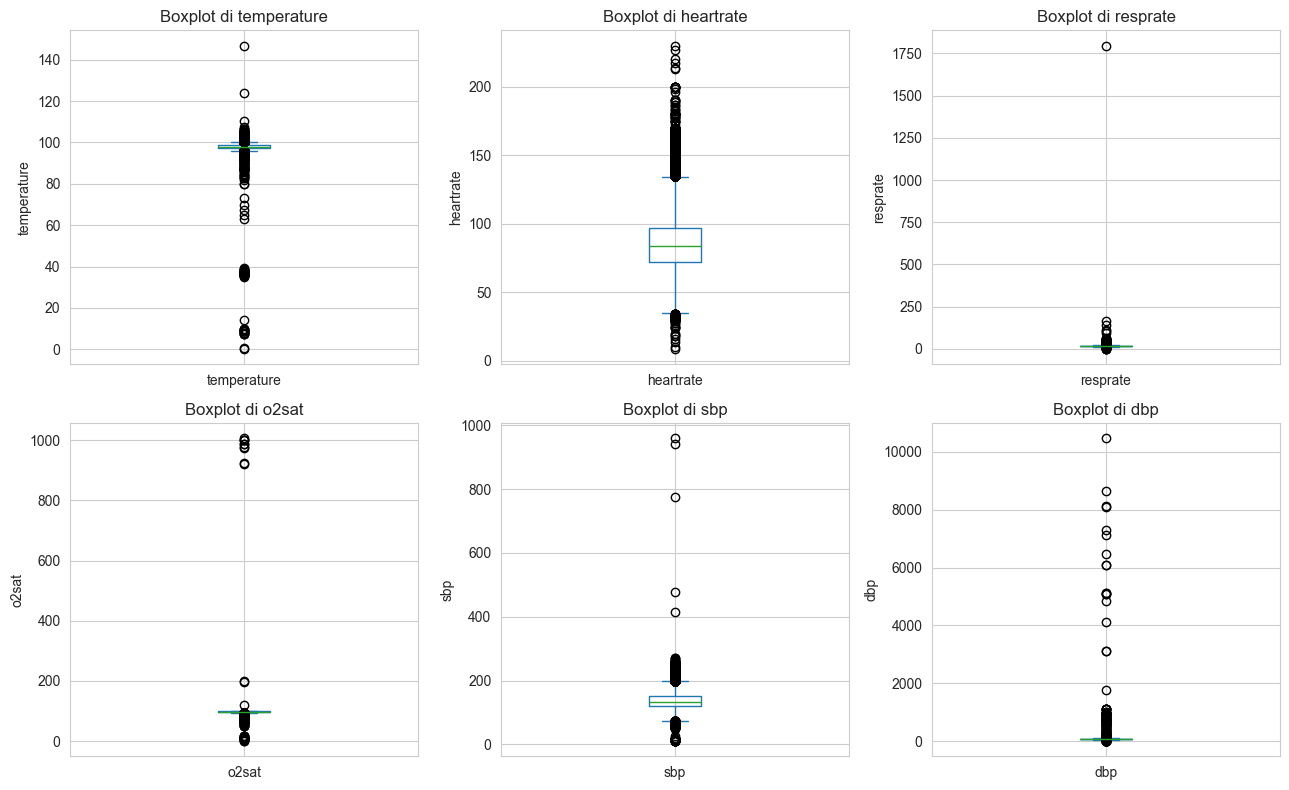

In [23]:
columns = ['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']
n_cols = 3
n_rows = 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 4 * n_rows))
for idx, col in enumerate(columns):
    row = idx // n_cols
    col_idx = idx % n_cols
    ax = axes[row, col_idx]
    triage_df[col].plot(kind='box', ax=ax, title=f'Boxplot di {col}')
    ax.set_ylabel(col)
for i in range(len(columns), n_rows * n_cols):
    fig.delaxes(axes.flat[i])
plt.tight_layout()
plt.show()


---
**Osservazione**: i valori normali dei seguenti attributi devono essere tra:

- `temperature` ([Human body temperature - Wikipedia](https://en.wikipedia.org/wiki/Human_body_temperature)):
	- Ipotermia severa: Inferiore a 82,4°F (28 °C)  
	- Ipotermia moderata: 82,4°F – 95°F (28-35 °C)  
	- Normale : 96.8 °F – 99.5 °F (36–37.5 °C)  
	- Febbre : 99.5 °F - 105.8°F  (37.5-41 °C)
	- Iperpiressia severa: Oltre 105.8°F (41 °C)
- `heartrate` (https://it.wikipedia.org/wiki/Frequenza_cardiaca):
	- bradicardia severa : inferiore a 40 bpm  
	- low heartrate : 40-60 bpm
	- normale (a risposo): 60-100 bpm   
	- high heartrate : 100-220 bpm
	- tachicardia severa : superiore a 220 bpm
- `resprate` (https://pmc.ncbi.nlm.nih.gov/articles/PMC7665156/):
	- Bradipnea severa : inferiore a 7 atti/min  
	- low resprate : 8-12 atti/min
	- normale : 12-20 atti/min   
	- high resprate : 20-35 atti/min
	- tachipnea severa : superiore a 35 atti/min
- `o2sat` (https://www.cosinuss.com/en/measured-data/vital-signs/oxygen-saturation/):
    - dato non valido : superiore a 100 %  
    - normale : 95-100 %
    - low o2sat : 90-95 %
    - o2sat critico (need hospitalization): 70-90 %
    - hypoxia severa: inferiore a 70 %
- `sbp` (https://www.medparkhospital.com/en-US/lifestyles/blood-pressure-readings):   
    - crisi ipertensive: superiore a 180 mmHg  
    - normale: tra 90 e 120 mmHg  
    - insufficienza cardiaca acuta: inferiore a 70 mmHg
- `dbp` (https://www.medparkhospital.com/en-US/lifestyles/blood-pressure-readings):
    - crisi ipertensive: superiore a 120 mmHg  
    - normale: tra 60 e 80 mmHg  
    - insufficienza cardiaca acuta: 40 mmHg

In [12]:
acceptable = triage_df[(triage_df['temperature'] >= 82) & (triage_df['temperature'] <= 105.8)]
triage_df_non_null = triage_df[triage_df['temperature'].notna()]
print("Numero di righe con temperatura accettale (82-105.8°F):", len(acceptable))
print("Num outlier :", len(triage_df_non_null) - len(acceptable))

Numero di righe con temperatura accettale (82-105.8°F): 97335
Num outlier : 151


In [13]:
acceptable = triage_df[(triage_df['heartrate'] >= 40) & (triage_df['heartrate'] <= 220)]
print("Numero di righe con heartrate accettale (40-220 bpm):", len(acceptable))
triage_df_non_null = triage_df[triage_df['heartrate'].notna()]
print("Num outlier :", len(triage_df_non_null) - len(acceptable))

Numero di righe con heartrate accettale (40-220 bpm): 99344
Num outlier : 249


In [14]:
acceptable = triage_df[(triage_df['resprate'] >= 8) & (triage_df['resprate'] <= 35)]
print("Numero di righe con resprate accettabile (8-35 atti):", len(acceptable))
triage_df_non_null = triage_df[triage_df['resprate'].notna()]
print("Num outlier :", len(triage_df_non_null) - len(acceptable))

Numero di righe con resprate accettabile (8-35 atti): 98282
Num outlier : 291


In [15]:
acceptable = triage_df[(triage_df['o2sat'] >= 70) & (triage_df['o2sat'] <= 100)]
print("Numero di righe con o2sat accettabile (70-100 atti):", len(acceptable))
triage_df_non_null = triage_df[triage_df['o2sat'].notna()]
print("Num outlier :", len(triage_df_non_null) - len(acceptable))

Numero di righe con o2sat accettabile (70-100 atti): 98475
Num outlier : 65


In [42]:
acceptable = triage_df[(triage_df['sbp'] >= 70) & (triage_df['sbp'] <= 180)]
print("Numero di righe con sbp accettabile (70-180 atti):", len(acceptable))
triage_df_non_null = triage_df[triage_df['sbp'].notna()]
print("Num outlier :", len(triage_df_non_null) - len(acceptable))

Numero di righe con sbp accettabile (70-180 atti): 94433
Num outlier : 11526


In [16]:
acceptable = triage_df[(triage_df['dbp'] >= 40) & (triage_df['dbp'] <= 120)]
print("Numero di righe con dbp accettabile (40-120 atti):", len(acceptable))
triage_df_non_null = triage_df[triage_df['dbp'].notna()]
print("Num outlier :", len(triage_df_non_null) - len(acceptable))

Numero di righe con dbp accettabile (40-120 atti): 97784
Num outlier : 1348


In [39]:
outlier = tmp_triage_df1[(tmp_triage_df1['resprate'] < 8) | (tmp_triage_df1['resprate'] > 35) | (tmp_triage_df1['temperature'] < 82) | (tmp_triage_df1['temperature'] > 105.8) | (tmp_triage_df1['heartrate'] < 40) | (tmp_triage_df1['heartrate'] > 220) | (tmp_triage_df1['o2sat'] < 70) | (tmp_triage_df1['o2sat'] > 100) | (tmp_triage_df1['sbp'] < 70) | (tmp_triage_df1['sbp'] > 180) | (tmp_triage_df1['dbp'] < 40) | (tmp_triage_df1['dbp'] > 120)]
print("Numero di righe non accettabili :", len(outlier))
print("Num accettabile :", len(tmp_triage_df1) - len(outlier))
print("Dataset totale di triage privo di NaN", len(tmp_triage_df1))
print("Percentuale restanti sul dataset triage.csv privo di NaN: ", (len(tmp_triage_df1) - len(outlier))/len(triage_df)*100)


Numero di righe non accettabili : 5896
Num accettabile : 88218
Dataset totale di triage privo di NaN 94114
Percentuale restanti sul dataset triage.csv privo di NaN:  83.25673137723082


In [41]:
tot_accettabile = triage_df[((triage_df['resprate'] < 8) & (triage_df['resprate'] > 35)) | ((triage_df['temperature'] < 82) & (triage_df['temperature'] > 105.8)) | ((triage_df['heartrate'] < 40) & (triage_df['heartrate'] > 220)) | (triage_df['o2sat'] < 70) | (triage_df['o2sat'] > 100) | (triage_df['sbp'] < 70) | (triage_df['sbp'] > 180) | (triage_df['dbp'] < 40) | (triage_df['dbp'] > 120)]
print("Numero di righe non accettabili nel dataset originale (senza cancellare i NaN):", len(tot_accettabile))
print("Percentuale restanti sul dataset triage.csv con i NaN: ", (len(triage_df) - len(tot_accettabile))/len(triage_df)*100)


Numero di righe non accettabili nel dataset originale (senza cancellare i NaN): 5886
Percentuale restanti sul dataset triage.csv con i NaN:  94.44502118744043


---
### **Unique values analysis and categorical**

In [251]:
# Visualizza i tipi di dati per identificare le colonne categoriali
print("Tipi di dati nel dataset:")
print(triage_df.dtypes)
print(triage_df.columns)

Tipi di dati nel dataset:
subject_id          int64
stay_id             int64
temperature       float64
heartrate         float64
resprate          float64
o2sat             float64
sbp               float64
dbp               float64
pain               object
acuity            float64
chiefcomplaint     object
dtype: object
Index(['subject_id', 'stay_id', 'temperature', 'heartrate', 'resprate',
       'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint'],
      dtype='object')


In [256]:
sub_column = ['pain', 'acuity', 'chiefcomplaint']
print(triage_df[sub_column][:10])

  pain  acuity                            chiefcomplaint
0    7     2.0                               Hypotension
1    0     3.0            Abd pain, Abdominal distention
2   10     3.0                           n/v/d, Abd pain
3   10     3.0                      Abdominal distention
4   13     2.0  Abdominal distention, Abd pain, LETHAGIC
5    7     3.0                               Head injury
6    0     3.0             Throat foreign body sensation
7    7     4.0                                L Hip pain
8    3     2.0                                  s/p Fall
9    0     2.0                              Hypoglycemia


In [211]:
# Conta i valori unici nelle colonne possibilmente categoriali
categorical_columns = ['acuity', 'chiefcomplaint', 'pain']
for col in categorical_columns:
    unique_count = triage_df[col].nunique()
    print(f"Numero di valori unici in '{col}':", unique_count)


Numero di valori unici in 'acuity': 5
Numero di valori unici in 'chiefcomplaint': 21662
Numero di valori unici in 'pain': 384


In [24]:
# Unique value comprehension
triage_column = ['pain', 'acuity', 'chiefcomplaint']
for column in triage_column:
    print(f"\t\t======= UNIQUE VALUE in [{column}] =======\n")
    print(triage_df[column].unique())
    print("\n\t\t=== Frequency of unique value ===\n")
    print(triage_df[column].value_counts())
    print("-" * 60, "\n")


		======= UNIQUE VALUE in [pain] =======

['7' '0' '10' '13' '3' '8' '4' '6' nan '5' '2' '1' 'Non-verbal' '9' 'ett'
 'unable' 'ua' 'Critical' 'uta' 'critical' '>10' '5-6' 'UA' 'UTA'
 'denies ' 'yes' 'ok' 'o' '7.5' 'leg pain' 'c' '3-4' 'unable ' '8.5'
 'crit' '9.5' 'Unable' 'alot' 'ETT' '?' ' 0' 'sore' '15-20' 'u' '20' '0 '
 'denies' '10 ' 'sedated' '2-3' '6-7' 'u/a' 'asleep' '___' 'Bad'
 'sleeping' 'unqble' 'UTA ' 'burning' '7-8' 'no' 'uta ' '6.5' 'pre-hosp'
 'UNABLE' 'unable to score - abd pain' '1.5' 'not much' 'very painful'
 '"pain"' 'not bad' 's' '3t' '0-10' '4-5' '8-9' '1-2' 'prehosp' '11'
 'uanble' '"hurts everywhere"' 'hurts' 'bad' 'pain' 'mild' '4 ' 'uable'
 'it hurts' 'yes - R arm' '0.5' '8 ' 'unable to rate' 'moderate'
 'refusing' 'Refused' 'unsure' 'trigger' '"yes"' '"15"' 'Unresponsive'
 '5.8' '12' '7/8' '-' 'unbale' '7.5-8' 'uts' '10+' '101' 'T' 'dull'
 'refused ' 'xc' '"alittle"' '"pains"' '0.' 'a lot' 'unable to score'
 '"alot"' '4.5' '-0' '"not bad" ' 'discomfort' '8/6

In [215]:
triage_df['acuity'] = pd.Categorical(triage_df['acuity'], categories=[1, 2, 3, 4, 5], ordered=True)
print("Distribuzione ordinata della gravità in 'acuity':")
print(triage_df['acuity'].value_counts().sort_index())


Distribuzione ordinata della gravità in 'acuity':
acuity
1     9941
2    46706
3    44259
4     2465
5       85
Name: count, dtype: int64


In [216]:
# Conta i valori mancanti nelle colonne categoriali
missing_values = triage_df[categorical_columns].isnull().sum()
print("Valori mancanti nelle colonne categoriali:")
print(missing_values)


Valori mancanti nelle colonne categoriali:
acuity            2503
chiefcomplaint       9
pain              4690
dtype: int64


In [190]:
triage_df['pain'].unique()

array(['7', '0', '10', '13', '3', '8', '4', '6', nan, '5', '2', '1',
       'Non-verbal', '9', 'ett', 'unable', 'ua', 'Critical', 'uta',
       'critical', '>10', '5-6', 'UA', 'UTA', 'denies ', 'yes', 'ok', 'o',
       '7.5', 'leg pain', 'c', '3-4', 'unable ', '8.5', 'crit', '9.5',
       'Unable', 'alot', 'ETT', '?', ' 0', 'sore', '15-20', 'u', '20',
       '0 ', 'denies', '10 ', 'sedated', '2-3', '6-7', 'u/a', 'asleep',
       '___', 'Bad', 'sleeping', 'unqble', 'UTA ', 'burning', '7-8', 'no',
       'uta ', '6.5', 'pre-hosp', 'UNABLE', 'unable to score - abd pain',
       '1.5', 'not much', 'very painful', '"pain"', 'not bad', 's', '3t',
       '0-10', '4-5', '8-9', '1-2', 'prehosp', '11', 'uanble',
       '"hurts everywhere"', 'hurts', 'bad', 'pain', 'mild', '4 ',
       'uable', 'it hurts', 'yes - R arm', '0.5', '8 ', 'unable to rate',
       'moderate', 'refusing', 'Refused', 'unsure', 'trigger', '"yes"',
       '"15"', 'Unresponsive', '5.8', '12', '7/8', '-', 'unbale', '7.5-8',


**Osservazione**: semantic cleaning: es. 'unaable', 'unablw', 'unbale', 'unqle'
- possible cleaning:
    - upper case -> lower case ('UNABLE' or 'Unable' -> 'unable')
    - strip space (es. ' 4' -> '4')
    - similarity (es. 'unaable' -> 'unable)
    - caratteri speciali e punteggiatura
    - correzione ortografica
    - stemming

**Osservazione**: Ci possono essere nomi uguali ma scritti con lower o upper case tipo \
'ABD PAIN' e 'Abd pain'

In [196]:
triage_df['chiefcomplaint'].unique()[:70]

array(['Hypotension', 'Abd pain, Abdominal distention', 'n/v/d, Abd pain',
       'Abdominal distention', 'Abdominal distention, Abd pain, LETHAGIC',
       'Head injury', 'Throat foreign body sensation', 'L Hip pain',
       's/p Fall', 'Hypoglycemia', 'DYSPNEA', 'Dyspnea', 'L Foot pain',
       'SOB', 'R FOOT BOIL', 'L Leg numbness', 'Anemia', 'FEVER',
       'PICC LINE INFECTION', 'LEFT HAND PAINS',
       'Abd pain, Nausea, Hypotension, Abdominal distention',
       'Abd pain, Transfer', 'Hematuria',
       'Back pain, R Flank pain, R Leg pain', 'Chest pain',
       'R Leg pain, R Pulseless foot', 'Head injury, s/p Fall',
       'Lethargy, Transfer', 'Psych eval',
       'Vaginal bleeding, Lower abdominal pain', 'HEMATURIA/RLQ PAIN',
       'Lower abdominal pain', 'LUQ abd pain', 'Wound eval',
       'Urinary retention', 'ABD PAIN', 'Rash', 'MID ABD PAIN/SPINE PAIN',
       'Altered mental status, s/p Fall, Transfer',
       'Constipation, Abd pain', 'TRAUMATIC BACK/SPINE INJURY',


---
### **Matrix Correlation**


In [197]:
triage_df.columns

Index(['subject_id', 'stay_id', 'temperature', 'heartrate', 'resprate',
       'o2sat', 'sbp', 'dbp', 'pain', 'acuity', 'chiefcomplaint'],
      dtype='object')

In [227]:
# Seleziona le colonne dei segni vitali
vital_signs = triage_df[['temperature', 'heartrate', 'resprate', 'o2sat', 'sbp', 'dbp']]


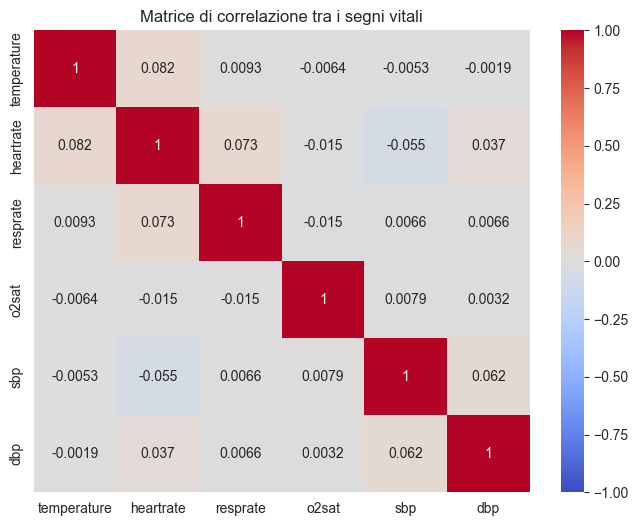

In [231]:
correlation_matrix = vital_signs.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matrice di correlazione tra i segni vitali")
plt.show()
